# Exercício 2 · Teste A/B do questionário de objetivos do Movimento

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

**GABARITO** · com prompts, código e leituras comentadas.

## O contexto

O **Movimento** é um app de treinos em casa por assinatura. Quem se cadastra ganha **7 dias grátis** e, depois disso, pode assinar o plano mensal. Hoje, o app abre direto numa lista de treinos.

O time de Produto criou um **questionário de objetivos** no primeiro acesso: o usuário responde 5 perguntas (objetivo, nível, tempo disponível, equipamentos, dias da semana) e recebe um plano de treino personalizado. A aposta é que um plano feito para a pessoa faz ela treinar mais e, por isso, assinar mais.

**O desenho do teste**

| Peça | Decisão |
|:---|:---|
| Unidade sorteada | O **usuário**, no cadastro: 50% controle (app atual), 50% tratamento (questionário) |
| Métrica primária (proporção) | `assinou_30d`: 1 se o usuário assinou o plano pago em até 30 dias após o cadastro |
| Métrica secundária (média) | `treinos_30d`: treinos concluídos nos 30 dias após o cadastro (0 para quem não treinou) |

As duas métricas são medidas para **todo usuário sorteado**, numa janela fixa a partir do cadastro de cada um.

**Os dados**

| Arquivo | O que tem |
|:---|:---|
| `historico_assinaturas.csv` | Usuários das 8 semanas antes do teste, todos com o app atual |
| `experimento_questionario.csv` | Usuários sorteados durante o teste, com a coluna `grupo` |

| Coluna | Descrição |
|:---|:---|
| `user_id` | Identificador do usuário |
| `grupo` | `controle` ou `tratamento` (só no experimento) |
| `data_cadastro` | Data do cadastro |
| `plataforma` | `android` ou `ios` |
| `treinos_30d` | Treinos concluídos em 30 dias |
| `assinou_30d` | 1 se assinou em até 30 dias, 0 caso contrário |

### Como usar este gabarito

Cada passo tem o **prompt** usado, o código gerado e a **leitura** do resultado. Os prompts são um exemplo: o importante é que digam **o que** a análise precisa fazer, não **como** codificar. **Todos os testes são bicaudais.**

## Parte 0 · Preparação

**Prompt para a IA**

> Vou analisar um teste A/B em Python. Prepare o ambiente com as bibliotecas que vamos usar para manipular dados, fazer gráficos e fazer estatística (testes de hipótese, intervalos de confiança e cálculo de tamanho de amostra). Sempre que possível, use funções prontas dessas bibliotecas, e escreva um código simples, para iniciantes.
> Deixe definidos os parâmetros do estudo: nível de significância de 5%, poder de 80%, menor efeito que importa (MDE) de 2 pontos percentuais na taxa de assinatura e de 1 treino na média de treinos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import (proportion_confint, proportions_ztest,
                                          confint_proportions_2indep, proportion_effectsize)

ALPHA = 0.05
PODER = 0.80
MDE_ASSIN = 0.02     # 2 pontos percentuais
MDE_TREINOS = 1.0    # 1 treino

**Prompt para a IA**

> Carregue os arquivos historico_assinaturas.csv (histórico) e experimento_questionario.csv (experimento), converta a coluna data_cadastro para data e mostre as primeiras linhas, o tamanho e os tipos das colunas do histórico.

In [ ]:
hist = pd.read_csv("historico_assinaturas.csv", parse_dates=["data_cadastro"])
exp = pd.read_csv("experimento_questionario.csv", parse_dates=["data_cadastro"])

print(hist.shape)
print(hist.dtypes)
hist.head()

(83615, 5)
user_id                     str
data_cadastro    datetime64[us]
plataforma                  str
treinos_30d               int64
assinou_30d               int64
dtype: object


,user_id,data_cadastro,plataforma,treinos_30d,assinou_30d
0,M100000,2026-05-04,android,8,0
1,M100001,2026-05-04,android,18,0
2,M100002,2026-05-04,android,0,0
3,M100003,2026-05-04,android,6,0
4,M100004,2026-05-04,android,7,0


## Parte 1 · As hipóteses e os riscos

Antes de olhar os dados, o time combinou:

| Ingrediente | Valor |
|:---|:---|
| Hipóteses (primária) | H0: p_trat = p_ctrl · Ha: p_trat ≠ p_ctrl |
| Hipóteses (secundária) | H0: μ_trat = μ_ctrl · Ha: μ_trat ≠ μ_ctrl |
| α | 5% |
| Poder | 80% |
| MDE da assinatura | +2 p.p. |
| MDE dos treinos | +1 treino em 30 dias |

**Por que bicaudal?** Um questionário no primeiro acesso é uma etapa a mais antes do primeiro treino. Ele pode ajudar (plano personalizado) ou atrapalhar (fricção, gente que desiste no meio). Se piorar a assinatura, o time precisa saber.

**Por que esses MDEs?** O questionário tem custo de desenvolvimento e manutenção, e só se paga com pelo menos +2 p.p. de assinatura. Um treino a mais por mês é o menor ganho de engajamento que o time considera relevante.

## Parte 2 · O estado atual (EDA do histórico)

**Prompt para a IA**

> No histórico, quero entender o fluxo de usuários: qual é o período coberto, quantos usuários há no total e quantos cadastros acontecem por dia (média, mínimo e máximo). Mostre também um gráfico dos cadastros ao longo dos dias.

Período: 2026-05-04 a 2026-06-28
Usuários: 83615
Cadastros por dia: média 1493 · mínimo 1198 · máximo 1944


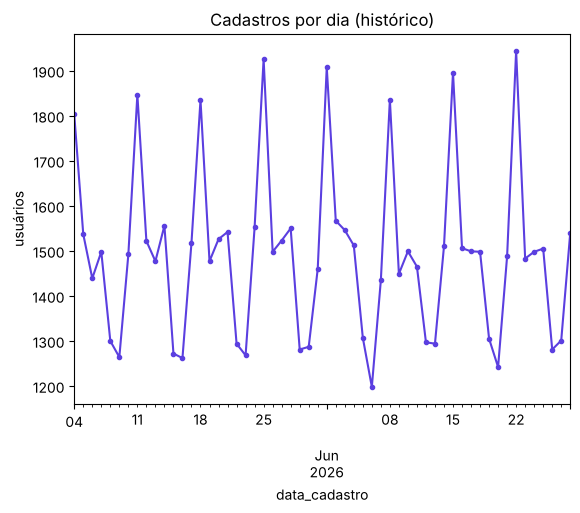

In [ ]:
print("Período:", hist["data_cadastro"].min().date(), "a", hist["data_cadastro"].max().date())
print("Usuários:", len(hist))

por_dia = hist.groupby("data_cadastro").size()
print(f"Cadastros por dia: média {por_dia.mean():.0f} · mínimo {por_dia.min()} · máximo {por_dia.max()}")

por_dia.plot(marker="o", markersize=3, color="#5B3FE0")
plt.title("Cadastros por dia (histórico)")
plt.ylabel("usuários")
plt.show()

> **Leitura.** O histórico cobre 8 semanas, com ~83.600 usuários e cerca de **1.500 cadastros por dia**. O gráfico tem um padrão semanal: as segundas-feiras concentram mais cadastros (quem decide "começar na segunda") e sextas e sábados têm menos. É um motivo para rodar o teste em **semanas completas**.

### 2.2 A métrica primária: assinatura em 30 dias

Para uma proporção, usamos o IC de Wilson. Com amostras deste tamanho, o de Wald daria praticamente o mesmo resultado.

**Prompt para a IA**

> No histórico, calcule a taxa de assinatura em 30 dias com o intervalo de confiança de 95% de Wilson. Depois mostre a taxa por semana de cadastro (com o número de usuários de cada semana) e por plataforma.

In [ ]:
x0 = hist["assinou_30d"].sum()
n0 = len(hist)
p0 = x0 / n0
ic_p0 = proportion_confint(x0, n0, alpha=ALPHA, method="wilson")
print(f"Taxa de assinatura: {p0:.2%}  ·  IC 95% (Wilson): {ic_p0[0]:.2%} a {ic_p0[1]:.2%}")
print()

semana = hist["data_cadastro"].dt.to_period("W")
print(hist.groupby(semana)["assinou_30d"].agg(["mean", "count"]))
print()
print(hist.groupby("plataforma")["assinou_30d"].mean())

Taxa de assinatura: 29.13%  ·  IC 95% (Wilson): 28.83% a 29.44%

                           mean  count
data_cadastro                         
2026-05-04/2026-05-10  0.284332  10333
2026-05-11/2026-05-17  0.292902  10454
2026-05-18/2026-05-24  0.292929  10494
2026-05-25/2026-05-31  0.292352  10525
2026-06-01/2026-06-07  0.293517  10473
2026-06-08/2026-06-14  0.295652  10350
2026-06-15/2026-06-21  0.285988  10434
2026-06-22/2026-06-28  0.293025  10552

plataforma
android    0.281533
ios        0.306105
Name: assinou_30d, dtype: float64


> **Leitura.** Hoje, **29,1%** dos usuários assinam em até 30 dias (IC de 28,8% a 29,4%), e a taxa é estável semana a semana. No iOS ela é um pouco maior que no Android (30,6% contra 28,2%). Isso não atrapalha o teste: o sorteio distribui as plataformas igualmente entre os grupos.

### 2.3 A métrica secundária: treinos em 30 dias

**Prompt para a IA**

> Agora os treinos concluídos em 30 dias, no histórico. Quero a média com o intervalo de confiança de 95%, o desvio-padrão, a porcentagem de usuários com zero treinos e os percentis 25, 50, 75, 90 e 95. Mostre um histograma da distribuição.

Média: 8.00 treinos  ·  IC 95%: 7.95 a 8.04
Desvio-padrão: 6.30
Usuários com zero treinos: 25.7%
Percentis:
0.25     0.0
0.50     8.0
0.75    12.0
0.90    16.0
0.95    19.0
Name: treinos_30d, dtype: float64


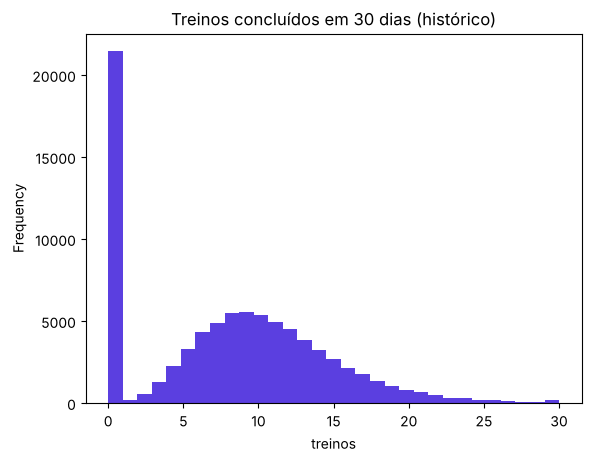

In [ ]:
treinos = hist["treinos_30d"]
mu0 = treinos.mean()
sigma0 = treinos.std()
ic_mu0 = stats.ttest_1samp(treinos, popmean=0).confidence_interval(confidence_level=1 - ALPHA)

print(f"Média: {mu0:.2f} treinos  ·  IC 95%: {ic_mu0.low:.2f} a {ic_mu0.high:.2f}")
print(f"Desvio-padrão: {sigma0:.2f}")
print(f"Usuários com zero treinos: {(treinos == 0).mean():.1%}")
print("Percentis:")
print(treinos.quantile([0.25, 0.50, 0.75, 0.90, 0.95]))

treinos.plot.hist(bins=31, color="#5B3FE0")
plt.title("Treinos concluídos em 30 dias (histórico)")
plt.xlabel("treinos")
plt.show()

> **Leitura.** Em média, um usuário conclui **8 treinos** nos primeiros 30 dias, com desvio de 6,3. Um quarto dos usuários (**25,7%**) não treina nenhuma vez: o percentil 25 é zero. Entre quem treina, a distribuição é razoavelmente simétrica, em torno de 10 treinos (a mediana geral é 8, o percentil 95 é 19). É uma métrica bem mais "comportada" que receita: sem cauda longa.

## Parte 3 · Tamanho mínimo de amostra

### 3.1 O piso do TLC: a regra de Kohavi

O cálculo de tamanho de amostra usa os quantis da Normal, então ele pressupõe que a média de cada grupo já se comporta como Normal. A regra de Kohavi dá o piso:

$$n > 355 \times \gamma^2$$

em que γ é a assimetria da métrica.

**Prompt para a IA**

> Antes de calcular o tamanho de amostra, quero saber o piso que o Teorema do Limite Central exige para cada métrica, pela regra de Kohavi: n > 355 × assimetria². Calcule a assimetria da assinatura e dos treinos no histórico e o n mínimo por grupo que a regra pede para cada uma.

In [ ]:
assim_assin = stats.skew(hist["assinou_30d"])
assim_trein = stats.skew(hist["treinos_30d"])
n_kohavi_assin = 355 * assim_assin**2
n_kohavi_trein = 355 * assim_trein**2

print(f"Assinatura: assimetria = {assim_assin:.2f}  ·  Kohavi pede n > {n_kohavi_assin:.0f}")
print(f"Treinos:    assimetria = {assim_trein:.2f}  ·  Kohavi pede n > {n_kohavi_trein:.0f}")

Assinatura: assimetria = 0.92  ·  Kohavi pede n > 299
Treinos:    assimetria = 0.40  ·  Kohavi pede n > 58


> **Leitura.** As duas métricas são pouco assimétricas: a assinatura (taxa perto de 30%) pede só ~300 usuários por grupo, e os treinos, ~60. O TLC não será problema aqui. Compare com a receita da Aprendiz, que pedia ~5.500: o piso de Kohavi pesa em métricas com cauda longa, não nestas.

### 3.2 Tamanho de amostra pelo poder

**Proporção:** o statsmodels e o G\*Power usam o h de Cohen (versão arco-seno da fórmula da aula).

**Média:** o efeito padronizado é o d de Cohen, d = MDE / σ, com σ do histórico.

**Prompt para a IA**

> Calcule o tamanho mínimo de amostra por grupo para as duas métricas, com nível de significância de 5%, poder de 80%, teste bicaudal e grupos do mesmo tamanho:
> 1. assinatura: taxa atual do histórico arredondada para 3 casas e aumento de 2 pontos percentuais; mostre as duas taxas e o tamanho do efeito;
> 2. treinos: aumento de 1 treino, com o desvio-padrão do histórico; mostre o d de Cohen.

In [ ]:
p1 = round(p0, 3)
p2 = p1 + MDE_ASSIN
h = proportion_effectsize(p2, p1)
n_assin = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=PODER, ratio=1)
print(f"Assinatura: p1 = {p1:.3f} · p2 = {p2:.3f} · h = {h:.4f} · n por grupo = {n_assin:.0f}")

d = MDE_TREINOS / sigma0
n_trein = TTestIndPower().solve_power(effect_size=d, alpha=ALPHA, power=PODER, ratio=1)
print(f"Treinos: σ = {sigma0:.2f} · d = {d:.4f} · n por grupo = {n_trein:.0f}")

Assinatura: p1 = 0.291 · p2 = 0.311 · h = 0.0436 · n por grupo = 8255
Treinos: σ = 6.30 · d = 0.1587 · n por grupo = 624


**No G\*Power**

| Campo | Assinatura | Treinos |
|:---|:---|:---|
| Test family | z tests | t tests |
| Statistical test | Proportions: Difference between two independent proportions | Means: Difference between two independent means (two groups) |
| Type of power analysis | A priori | A priori |
| Tail(s) | **Two** | **Two** |
| Parâmetros do efeito | p1 = 0.291 · p2 = 0.311 | Effect size d ≈ 0.159 |
| α err prob · Power | 0.05 · 0.80 | 0.05 · 0.80 |
| Allocation ratio N2/N1 | 1 | 1 |

Atenção ao campo **Tail(s)**: em "One", o G\*Power calcula um teste unicaudal e devolve um n bem menor.

**Prompt para a IA**

> Junte tudo: o teste precisa respeitar o piso de Kohavi das duas métricas e ter poder para as duas. Mostre uma tabela com os quatro valores calculados, defina o n por grupo como o maior deles, o total de usuários e quantos dias o teste precisa rodar com a média de cadastros por dia do histórico, arredondando para semanas completas.

In [ ]:
candidatos = pd.Series({"Kohavi · assinatura": n_kohavi_assin, "Kohavi · treinos": n_kohavi_trein,
                        "Poder · assinatura": n_assin, "Poder · treinos": n_trein}).round()
print(candidatos)

n_por_grupo = int(np.ceil(candidatos.max()))
n_total = 2 * n_por_grupo
dias = n_total / por_dia.mean()
semanas = int(np.ceil(dias / 7))
print(f"\nn por grupo: {n_por_grupo} · total: {n_total}")
print(f"Dias necessários: {dias:.1f} → rodar {semanas} semanas completas ({7 * semanas} dias)")

Kohavi · assinatura     299.0
Kohavi · treinos         58.0
Poder · assinatura     8255.0
Poder · treinos         624.0
dtype: float64

n por grupo: 8255 · total: 16510
Dias necessários: 11.1 → rodar 2 semanas completas (14 dias)


> **Leitura.** Quem manda é a **assinatura**: ~8.300 usuários por grupo, contra ~620 para os treinos. É comum: detectar 2 p.p. numa taxa de 30% exige muito mais dados do que detectar 1 treino numa métrica com desvio de 6. Com ~1.500 cadastros por dia, são 11 dias, e o teste roda **2 semanas completas**. Como cada usuário precisa de 30 dias de acompanhamento, a análise sai 30 dias depois do último cadastro.

## Parte 4 · O experimento: checagens

**Prompt para a IA**

> Agora os dados do experimento. Mostre o período do teste e quantos usuários caíram em cada grupo, diga se os dois grupos atingiram o tamanho de amostra planejado e teste se a divisão é compatível com 50/50 (mostre o p-valor). Depois compare a distribuição de plataforma entre os grupos, em porcentagem de cada grupo.

In [ ]:
print("Período:", exp["data_cadastro"].min().date(), "a", exp["data_cadastro"].max().date())

contagem = exp["grupo"].value_counts()
print(contagem)
print("Atingiu o n planejado?", contagem.min() >= n_por_grupo)

teste_50 = stats.binomtest(contagem["tratamento"], contagem.sum(), p=0.5)
print(f"Teste da divisão 50/50: p = {teste_50.pvalue:.2f}")
print()
print(pd.crosstab(exp["plataforma"], exp["grupo"], normalize="columns"))

Período: 2026-07-06 a 2026-07-19
grupo
controle      10491
tratamento    10404
Name: count, dtype: int64
Atingiu o n planejado? True
Teste da divisão 50/50: p = 0.55



grupo       controle  tratamento
plataforma                      
android     0.598608     0.60371
ios         0.401392     0.39629


> **Leitura.** Os dois grupos passaram de 10 mil usuários, acima dos ~8.300 planejados. A divisão é compatível com 50/50 (p = 0,55: nenhum sinal de SRM) e as plataformas estão distribuídas da mesma forma nos dois grupos. O sorteio funcionou: a única diferença sistemática entre os grupos é o questionário.

## Parte 5 · Métrica primária: assinatura

**O IC da diferença:**

$$\hat{\delta} \pm 1{,}96 \sqrt{\frac{\hat{p}_1(1-\hat{p}_1)}{n_1} + \frac{\hat{p}_2(1-\hat{p}_2)}{n_2}}$$

**O teste z** usa o erro-padrão combinado, porque é calculado no multiverso de H0, onde as duas taxas são iguais.

**A tabela de significância prática:**

| O que o IC mostra | Leitura | Decisão típica |
|:---|:---|:---|
| Exclui o zero e está todo além do MDE | Real e relevante | Lançar |
| Exclui o zero, mas fica aquém do MDE | Real, pequeno demais | Não lançar (ou rever custo) |
| Inclui o zero, estreito, aquém do MDE | Se houver, não importa | Não lançar |
| Inclui o zero, largo, alcança o MDE | Inconclusivo | Mais amostra ou investigar |

**Prompt para a IA**

> Separe os usuários do controle e do tratamento. Para a taxa de assinatura em 30 dias, calcule a taxa de cada grupo com o intervalo de confiança de 95% de Wilson. Depois calcule a diferença (tratamento − controle) em pontos percentuais com o intervalo de confiança de 95% (Wald) e faça o teste z para duas proporções, bicaudal, mostrando a estatística z e o p-valor.

In [ ]:
ctrl = exp[exp["grupo"] == "controle"]
trat = exp[exp["grupo"] == "tratamento"]

x1, n1 = ctrl["assinou_30d"].sum(), len(ctrl)
x2, n2 = trat["assinou_30d"].sum(), len(trat)
p1_hat, p2_hat = x1 / n1, x2 / n2

ic1 = proportion_confint(x1, n1, alpha=ALPHA, method="wilson")
ic2 = proportion_confint(x2, n2, alpha=ALPHA, method="wilson")
print(f"Controle:   {p1_hat:.2%}  IC 95% [{ic1[0]:.2%} ; {ic1[1]:.2%}]")
print(f"Tratamento: {p2_hat:.2%}  IC 95% [{ic2[0]:.2%} ; {ic2[1]:.2%}]")

dif = p2_hat - p1_hat
ic_dif = confint_proportions_2indep(x2, n2, x1, n1, method="wald")
z, p_valor = proportions_ztest([x2, x1], [n2, n1])
print(f"\nDiferença: {dif * 100:+.2f} p.p.  ·  IC 95%: [{ic_dif[0] * 100:+.2f} ; {ic_dif[1] * 100:+.2f}] p.p.")
print(f"z = {z:.2f}  ·  p-valor = {p_valor:.2f}")

Controle:   29.09%  IC 95% [28.23% ; 29.97%]
Tratamento: 28.96%  IC 95% [28.10% ; 29.84%]

Diferença: -0.13 p.p.  ·  IC 95%: [-1.36 ; +1.10] p.p.
z = -0.21  ·  p-valor = 0.83


**Prompt para a IA**

> Desenhe o intervalo de confiança da diferença de assinatura como uma barra horizontal, com um ponto na diferença observada, uma linha tracejada no zero e outra no MDE de 2 p.p. Deixe o gráfico pronto para reaproveitar na outra métrica.

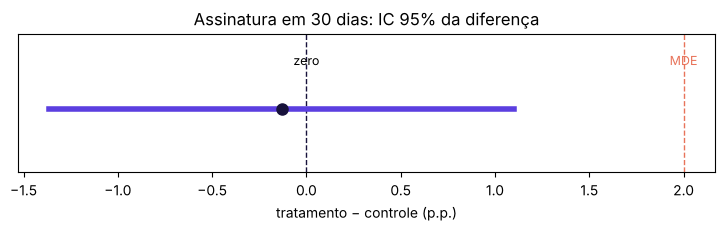

In [ ]:
def plot_ic(estimativa, lo, hi, mde, titulo, rotulo_x):
    plt.figure(figsize=(9, 1.8))
    plt.axvline(0, color="#17123B", linestyle="--", linewidth=1)
    plt.axvline(mde, color="#E8735A", linestyle="--", linewidth=1)
    plt.text(0, 1.35, "zero", ha="center", fontsize=9)
    plt.text(mde, 1.35, "MDE", ha="center", fontsize=9, color="#E8735A")
    plt.plot([lo, hi], [1, 1], color="#5B3FE0", linewidth=4)
    plt.plot(estimativa, 1, "o", color="#17123B", markersize=8)
    plt.ylim(0.5, 1.6)
    plt.yticks([])
    plt.xlabel(rotulo_x)
    plt.title(titulo)
    plt.show()

plot_ic(dif * 100, ic_dif[0] * 100, ic_dif[1] * 100, MDE_ASSIN * 100,
        "Assinatura em 30 dias: IC 95% da diferença", "tratamento − controle (p.p.)")

> **Leitura.** A taxa de assinatura praticamente não mudou: **29,1%** no controle e **29,0%** no tratamento, uma diferença de −0,1 p.p. O p-valor é alto (≈ 0,83): não rejeitamos H0.
>
> Mas aqui o "não significativo" diz mais que o habitual. O IC vai de **−1,4 a +1,1 p.p.**: ele inclui o zero **e é estreito**, todo abaixo do MDE de 2 p.p. É a terceira linha da tabela: **se o questionário muda a assinatura, a mudança é pequena demais para importar**. Diferente de um resultado inconclusivo, este teste tinha amostra suficiente para enxergar o efeito que o time queria, e ele não apareceu.

## Parte 6 · Métrica secundária: treinos

**O teste t de Welch** não supõe variâncias iguais entre os grupos e é o padrão para comparar duas médias:

$$t = \frac{\bar{x}_2 - \bar{x}_1}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}$$

**Prompt para a IA**

> Para os treinos em 30 dias, mostre por grupo o número de usuários, a média, o desvio-padrão e a porcentagem com zero treinos. Depois faça o teste t de Welch, bicaudal, e mostre a diferença de médias (tratamento − controle), a estatística t, o p-valor e o intervalo de confiança de 95% da diferença. Use o mesmo gráfico do IC com o zero e o MDE de 1 treino.

            count      mean      std    % zero
grupo                                         
controle    10491  8.006291  6.31674  0.255838
tratamento  10404  9.257401  7.21950  0.257497

Diferença: +1.25 treinos  ·  t = 13.33  ·  p-valor = 2.4e-40
IC 95%: [+1.07 ; +1.44] treinos


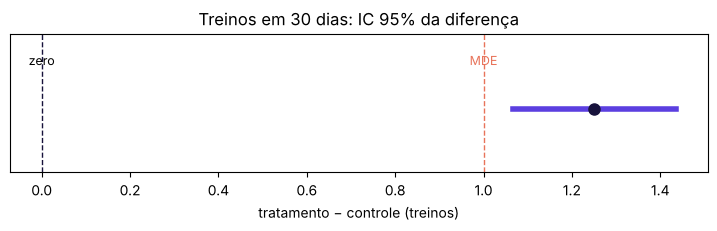

In [ ]:
tc = ctrl["treinos_30d"]
tt = trat["treinos_30d"]

resumo = exp.groupby("grupo")["treinos_30d"].agg(["count", "mean", "std"])
resumo["% zero"] = exp.groupby("grupo")["treinos_30d"].apply(lambda t: (t == 0).mean())
print(resumo)

dif_t = tt.mean() - tc.mean()
res = stats.ttest_ind(tt, tc, equal_var=False)
ic_t = res.confidence_interval(confidence_level=1 - ALPHA)
print(f"\nDiferença: {dif_t:+.2f} treinos  ·  t = {res.statistic:.2f}  ·  p-valor = {res.pvalue:.2g}")
print(f"IC 95%: [{ic_t.low:+.2f} ; {ic_t.high:+.2f}] treinos")

plot_ic(dif_t, ic_t.low, ic_t.high, MDE_TREINOS,
        "Treinos em 30 dias: IC 95% da diferença", "tratamento − controle (treinos)")

> **Leitura.** O questionário aumentou o engajamento: a média de treinos em 30 dias subiu de **8,0 para 9,3**, uma diferença de **+1,25 treino**, com p-valor minúsculo. O IC vai de **+1,07 a +1,44**: exclui o zero e está **todo acima do MDE** de 1 treino. É a primeira linha da tabela: **real e relevante**. O plano personalizado fez as pessoas treinarem mais.

## Parte 7 · A decisão

**Prompt para a IA**

> Monte a tabela final do relatório, com uma linha para cada métrica (assinatura e treinos) e as colunas: controle, tratamento, diferença, IC de 95%, p-valor, MDE e leitura pela tabela de significância prática. Formate os números para facilitar a leitura.

In [ ]:
relatorio = pd.DataFrame({
    "métrica": ["Assinatura em 30 dias (primária)", "Treinos em 30 dias (secundária)"],
    "controle": [f"{p1_hat:.1%}", f"{tc.mean():.2f}"],
    "tratamento": [f"{p2_hat:.1%}", f"{tt.mean():.2f}"],
    "diferença": [f"{dif * 100:+.1f} p.p.", f"{dif_t:+.2f}"],
    "IC 95%": [f"[{ic_dif[0] * 100:+.1f} ; {ic_dif[1] * 100:+.1f}] p.p.", f"[{ic_t.low:+.2f} ; {ic_t.high:+.2f}]"],
    "p-valor": [f"{p_valor:.2f}", f"{res.pvalue:.1g}"],
    "MDE": ["+2 p.p.", "+1 treino"],
    "leitura": ["Se houver efeito, é pequeno demais", "Real e relevante"],
})
relatorio

,métrica,controle,tratamento,diferença,IC 95%,p-valor,MDE,leitura
0,Assinatura em 30 dias (primária),29.1%,29.0%,-0.1 p.p.,[-1.4 ; +1.1] p.p.,0.83,+2 p.p.,"Se houver efeito, é pequeno demais"
1,Treinos em 30 dias (secundária),8.01,9.26,+1.25,[+1.07 ; +1.44],2e-40,+1 treino,Real e relevante


**Recomendação.** **Não lançar** o questionário como está, apesar do ganho de engajamento.

- A **métrica primária**, que decide, mostra que o questionário não muda a assinatura de forma relevante: o IC (−1,4 a +1,1 p.p.) descarta o ganho de 2 p.p. que pagaria a mudança. Não é falta de amostra: o teste tinha poder para enxergar esse efeito.
- A **métrica secundária** mostra um ganho real de engajamento: +1,25 treino por usuário, todo acima do MDE. As pessoas treinam mais, mas isso não virou assinatura dentro de 30 dias.
- **Próximo passo:** o questionário funciona para o que foi desenhado (engajar), mas o engajamento a mais não chega na decisão de pagar. Vale investigar onde a jornada trava: o paywall no fim dos 7 dias? o preço? E acompanhar se os usuários que treinaram mais retêm melhor depois de assinar, o que poderia justificar o questionário por outro caminho (retenção, e não conversão).
